# 04 - Modéliser la sanction : à caractéristiques égales

Le notebook 03 comparait les sortants visés par une affaire à des sortants de
communes de même taille. Trois raisons imposent d'aller plus loin :

1. **Le retour vers la moyenne.** Un sortant élu avec 70 % des voix a plus à perdre
   qu'un sortant élu de justesse. Il faut tenir compte de son score précédent.
2. **Le contexte local.** Le diplôme, la catégorie sociale, l'âge des habitants et le
   vote à la présidentielle pèsent sur la stabilité du vote municipal
   (`src/covariables.py`, recensement de l'INSEE et présidentielles 2017 et 2022).
3. **La notoriété.** Les sortants « avec affaire » sont presque tous des personnalités
   (Wikipédia, Poligraph). Pour séparer l'effet de l'affaire de celui de la notoriété,
   on utilise une variable `personnalite_affaires` : la personne figure dans nos
   sources d'affaires, que son affaire soit connue au moment du vote ou non. Le
   coefficient de l'affaire compare alors un sortant visé par une affaire connue à
   une personnalité du même type dont l'affaire n'était pas encore sortie.

On estime des régressions linéaires (évolution du score), des régressions
logistiques (victoire), puis un appariement sur le score de propension. Les
erreurs-types sont groupées par commune, car une même commune apparaît en 2020 et en 2026.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # notebook lancé depuis notebooks/
sys.path.insert(0, str(ROOT / "src"))
import modeles as M  # noqa: E402

pd.set_option("display.width", 200)

COULEURS = {2020: "#2a78d6", 2026: "#eb6834"}
ENCRE, NEUTRE = "#52514e", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": NEUTRE, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": ENCRE, "ytick.color": ENCRE,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

d = M.table_modele()
print(f"{len(d)} sortants x élection ; affaire connue au vote : {d.affaire_connue.sum()} "
      f"(dont révélée pendant le mandat : {d.affaire_mandat.sum()}) ; "
      f"personnalités recensées : {d.personnalite_affaires.sum()}")

6772 sortants x élection ; affaire connue au vote : 57 (dont révélée pendant le mandat : 30) ; personnalités recensées : 103


## 1. Des sortants très différents des autres

Moyennes des caractéristiques selon le groupe. Les « personnalités sans affaire
connue » sont celles dont l'affaire n'éclatera qu'après le scrutin.

In [2]:
groupe = np.select([d.affaire_connue == 1, d.personnalite_affaires == 1],
                   ["affaire connue au vote", "personnalité, affaire future"], "autres sortants")
cols = {"inscrits": "inscrits", "pct_voix_exp_prec": "score précédent (%)", "n_listes": "listes",
        "pct_diplome_sup": "diplômés du sup. (%)", "pct_cadres": "cadres (%)",
        "pct_retraites": "retraités (%)", "pct_extreme_droite_pres": "extrême droite présid. (%)",
        "delta_pct_voix_exp": "évolution du score (pts)", "gagne": "victoire"}
(d.assign(groupe=groupe).groupby("groupe")[list(cols)].mean().rename(columns=cols)
 .assign(effectif=pd.Series(groupe).value_counts()).T.round(2))

groupe,affaire connue au vote,autres sortants,"personnalité, affaire future"
inscrits,35412.631579,5472.756335,43403.152174
score précédent (%),52.039825,62.097296,50.134565
listes,5.210526,2.645224,5.565217
diplômés du sup. (%),34.597483,28.692422,31.189202
cadres (%),11.756485,8.164015,9.381743
retraités (%),25.743272,30.329573,26.126063
extrême droite présid. (%),27.189871,29.289208,20.11642
évolution du score (pts),-1.112982,-7.312084,1.037609
victoire,0.807018,0.735193,0.934783
effectif,57,6669,46


**Lecture.** Les sortants visés par une affaire dirigent des villes six fois plus peuplées que les autres (35 000 inscrits en moyenne contre 5 500), où la compétition est plus forte (5 listes contre 2,6) et le sortant moins bien élu au départ (52 % contre 62 %). Leurs électeurs sont plus diplômés et votent moins à l'extrême droite. Surtout, les **personnalités dont l'affaire n'éclatera qu'après le vote** leur ressemblent beaucoup, mais font nettement mieux : leur score progresse (+1 point) et elles gagnent 93 % du temps. C'est la meilleure référence pour isoler l'effet de l'affaire.

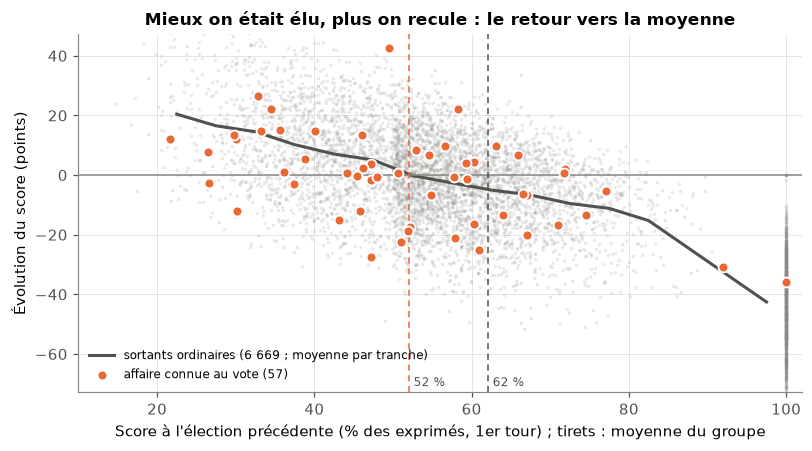

In [3]:
import graphiques as G  # noqa: E402

G.retour_moyenne(d)
plt.show()

**Lecture.** Chaque point gris est un sortant ordinaire ; la courbe donne leur évolution
moyenne selon le score obtenu à l'élection précédente. Un sortant élu avec 30 % des voix
progresse en moyenne d'une quinzaine de points, un sortant élu avec 75 % en perd une
dizaine : c'est le **retour vers la moyenne**. Les sortants visés par une affaire (en
orange) avaient été moins bien élus que les autres (52 % contre 62 % en moyenne), mais à
score précédent égal ils se répartissent de part et d'autre de la courbe des sortants
ordinaires : rien ne les en écarte nettement. Toute comparaison qui ignore le score
précédent mélange donc l'effet de l'affaire et celui de ce point de départ.

## 2. Évolution du score : régressions linéaires

On ajoute les variables pas à pas pour voir ce que chacune change :

- (1) affaire connue au vote + contrôles (score précédent, taille, nombre de listes,
  élection, bord politique, contexte socio-économique et présidentiel) ;
- (2) + notoriété (`personnalite_affaires`) ;
- (3) affaire révélée pendant le mandat / connue avant le mandat ;
- (4) + atteinte à la probité, condamnation déjà prononcée.

In [4]:
FORMULES = {
    "(1)": "delta_pct_voix_exp ~ affaire_connue + " + M.CONTROLES,
    "(2)": "delta_pct_voix_exp ~ affaire_connue + personnalite_affaires + " + M.CONTROLES,
    "(3)": "delta_pct_voix_exp ~ affaire_mandat + affaire_avant_mandat + personnalite_affaires + " + M.CONTROLES,
    "(4)": ("delta_pct_voix_exp ~ affaire_mandat + affaire_avant_mandat + affaire_probite_connue"
            " + condamne_avant + personnalite_affaires + " + M.CONTROLES),
}
ols = {nom: M.ols(f, d) for nom, f in FORMULES.items()}

def tableau(resultats: dict) -> pd.DataFrame:
    """Coefficient (erreur-type) et étoiles, une colonne par modèle."""
    lignes = {}
    for nom, r in resultats.items():
        for var in r.params.index:
            if var == "Intercept" or var.startswith("C("):
                continue
            etoiles = "***" if r.pvalues[var] < 0.01 else "**" if r.pvalues[var] < 0.05 else \
                "*" if r.pvalues[var] < 0.1 else ""
            lignes.setdefault(var, {})[nom] = f"{r.params[var]:.2f}{etoiles} ({r.bse[var]:.2f})"
        lignes.setdefault("observations", {})[nom] = f"{int(r.nobs)}"
        lignes.setdefault("R²", {})[nom] = f"{r.rsquared:.3f}"
    t = pd.DataFrame(lignes).T.fillna("")
    interet = t.index.str.contains("affaire|personnalite|condamne")
    return pd.concat([t[interet], t[~interet]])

tableau(ols)

,(1),(2),(3),(4)
affaire_connue,5.13*** (1.92),-1.18 (2.54),,
personnalite_affaires,,6.71*** (1.97),6.71*** (1.97),6.73*** (1.97)
affaire_mandat,,,-3.18 (2.56),-3.44 (4.19)
affaire_avant_mandat,,,1.02 (3.68),1.40 (5.49)
affaire_probite_connue,,,,3.59 (3.69)
condamne_avant,,,,-2.71 (3.85)
pct_voix_exp_prec,-0.89*** (0.01),-0.89*** (0.01),-0.89*** (0.01),-0.89*** (0.01)
log_inscrits,5.75*** (0.28),5.65*** (0.28),5.64*** (0.28),5.64*** (0.28)
n_listes,-7.56*** (0.23),-7.61*** (0.24),-7.61*** (0.23),-7.61*** (0.23)
pct_diplome_sup,-0.02 (0.04),-0.02 (0.04),-0.02 (0.04),-0.02 (0.04)


**Lecture.** Le score précédent pèse lourd : chaque point gagné en 2014 ou en 2020 est presque entièrement « rendu » à l'élection suivante (coefficient -0,89). C'est le retour vers la moyenne, et le contrôler change tout.

- **Modèle (1).** À score précédent, taille et contexte égaux, une affaire connue au vote est associée à **+5 points** (significatif à 1 %). Ce n'est pas une prime à l'affaire : c'est la notoriété.
- **Modèle (2).** Le fait d'être une personnalité recensée rapporte à lui seul +6,7 points. Une fois cette notoriété prise en compte, l'affaire devient légèrement **négative** (-1,2 point) et non significative.
- **Modèle (3).** C'est l'affaire révélée pendant le mandat qui coûte le plus (-3,2 points), mais l'intervalle de confiance contient zéro.
- **Modèle (4).** Ni la nature de l'affaire (probité) ni une condamnation déjà prononcée ne changent significativement le résultat.

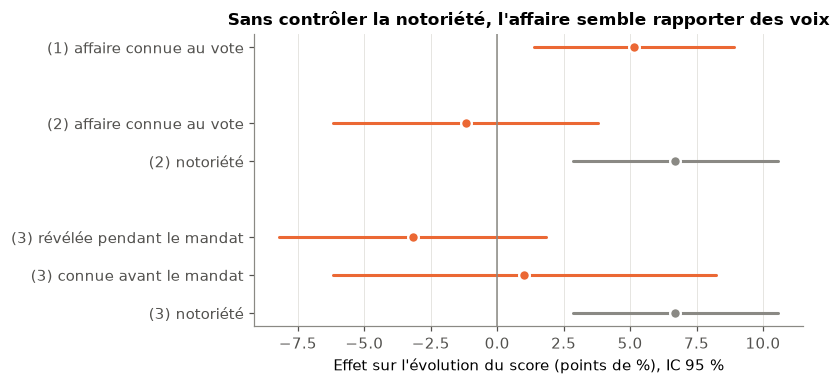

In [5]:
# Ce que change l'ajout de la notoriété : coefficients des modèles (1) à (3).
variables = {"affaire_connue": "affaire connue au vote", "affaire_mandat": "révélée pendant le mandat",
             "affaire_avant_mandat": "connue avant le mandat", "personnalite_affaires": "notoriété"}
lignes = []
for nom in ("(1)", "(2)", "(3)"):
    r, ic = ols[nom], ols[nom].conf_int()
    lignes += [(f"{nom} {lib}", r.params[v], ic.loc[v, 0], ic.loc[v, 1], v == "personnalite_affaires")
               for v, lib in variables.items() if v in r.params]
    lignes.append(None)  # espace entre modèles
lignes = lignes[:-1]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ticks, labels = [], []
for y, ligne in enumerate(lignes):
    if ligne is None:
        continue
    lib, coef, bas, haut, notoriete = ligne
    couleur = NEUTRE if notoriete else COULEURS[2026]
    ax.plot([bas, haut], [y, y], color=couleur, lw=2, solid_capstyle="round")
    ax.plot(coef, y, "o", ms=7, color=couleur, mec="white", mew=1.5)
    ticks.append(y)
    labels.append(lib)
ax.set_yticks(ticks, labels)
ax.invert_yaxis()
ax.axvline(0, color=NEUTRE, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effet sur l'évolution du score (points de %), IC 95 %")
ax.set_title("Sans contrôler la notoriété, l'affaire semble rapporter des voix")
plt.tight_layout()
plt.show()

## 3. Victoire : régressions logistiques

Mêmes variables, résultat binaire (la liste du sortant l'emporte). On présente les
**effets marginaux moyens** : de combien de points de pourcentage la probabilité de
gagner change quand la variable passe de 0 à 1.

In [6]:
logits = {nom: M.logit(f.replace("delta_pct_voix_exp ~", "gagne ~"), d) for nom, f in FORMULES.items()}
pd.concat({nom: M.coefficients(r) for nom, r in logits.items()}).round(3)

coef  ic_bas  ic_haut      p
(1) affaire_connue          0.073  -0.063    0.209  0.294
(2) affaire_connue         -0.220  -0.493    0.053  0.113
    personnalite_affaires   0.306   0.068    0.544  0.012
(3) affaire_mandat         -0.293  -0.575   -0.012  0.041
    affaire_avant_mandat   -0.090  -0.442    0.263  0.618
    personnalite_affaires   0.306   0.068    0.544  0.012
(4) affaire_mandat         -0.314  -0.722    0.094  0.131
    affaire_avant_mandat   -0.036  -0.501    0.429  0.879
    affaire_probite_connue  0.374   0.062    0.687  0.019
    personnalite_affaires   0.306   0.068    0.544  0.012

**Lecture.** Sur la victoire, le modèle (3) donne le résultat le plus net de l'étude : à notoriété égale, une affaire révélée pendant le mandat **réduit de 29 points la probabilité de gagner** (IC 95 % : de -57 à -1 point, p = 0,04). Mais la notoriété l'augmente d'autant (+31 points). Au total, un sortant visé par une affaire gagne à peu près aussi souvent qu'un sortant ordinaire, mais beaucoup moins souvent qu'une personnalité comparable sans affaire.

Le modèle (4) attribue un effet positif aux affaires de probité (+37 points). Elles ne concernent qu'une quinzaine de sortants, et ce chiffre reflète surtout quelques maires de grandes villes réélus malgré une affaire : il ne faut pas le surinterpréter.

## 4. Participation

Une affaire peut aussi démobiliser les électeurs, ou au contraire les mobiliser. On
explique l'évolution de la participation au 1er tour (en points), avec les mêmes contrôles.

In [7]:
part = M.ols("delta_participation ~ affaire_mandat + affaire_avant_mandat + personnalite_affaires + "
             + M.CONTROLES, d.dropna(subset=["delta_participation"]))
M.coefficients(part).assign(coef_points=lambda t: 100 * t.coef if d.participation.max() <= 1 else t.coef).round(3)

,coef,ic_bas,ic_haut,p,coef_points
affaire_mandat,0.017,-0.013,0.048,0.264,1.748
affaire_avant_mandat,0.006,-0.022,0.034,0.662,0.623
personnalite_affaires,-0.018,-0.036,0.001,0.066,-1.758


**Lecture.** Exprimée en points de participation (colonne `coef_points`), une affaire révélée pendant le mandat est associée à une participation un peu plus élevée (+1,7 point), sans que ce soit significatif. Les données ne montrent ni démobilisation ni sursaut civique notable.

## 5. L'électeur oublie-t-il ? Le délai entre l'affaire et le vote

Parmi les sortants dont l'affaire était connue au moment du vote, on regarde si la
sanction dépend du temps écoulé depuis la première affaire.

,sortants,evolution_score,victoire
delai,,,
< 1 an,4,-11.58,0.75
1-3 ans,11,1.00,0.64
3-6 ans,10,-6.51,0.70
> 6 ans,32,1.16,0.91


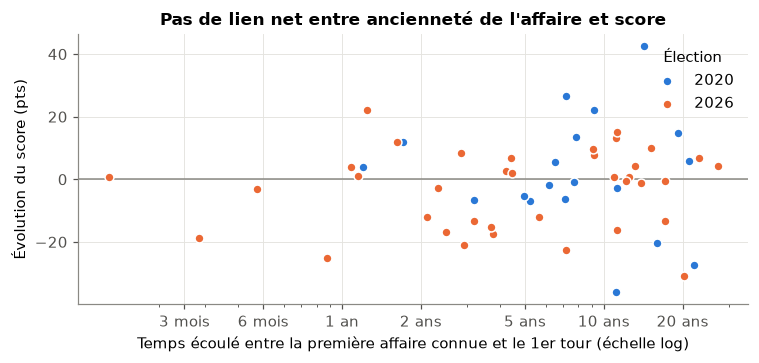

In [8]:
traites = d[d.affaire_connue == 1].copy()
traites["delai"] = pd.cut(traites.delai_annees, [0, 1, 3, 6, np.inf],
                          labels=["< 1 an", "1-3 ans", "3-6 ans", "> 6 ans"])
display(traites.groupby("delai", observed=True)
        .agg(sortants=("code_insee", "size"), evolution_score=("delta_pct_voix_exp", "mean"),
             victoire=("gagne", "mean")).round(2))

fig, ax = plt.subplots(figsize=(7, 3.4))
for annee, g in traites.groupby("annee"):
    ax.scatter(g.delai_annees, g.delta_pct_voix_exp, s=34, color=COULEURS[annee], edgecolor="white",
               linewidth=1, label=str(annee), zorder=3)
ax.axhline(0, color=NEUTRE, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 5, 10, 20], ["3 mois", "6 mois", "1 an", "2 ans", "5 ans", "10 ans", "20 ans"])
ax.set_xlabel("Temps écoulé entre la première affaire connue et le 1er tour (échelle log)")
ax.set_ylabel("Évolution du score (pts)")
ax.set_title("Pas de lien net entre ancienneté de l'affaire et score")
ax.legend(title="Élection")
plt.tight_layout()
plt.show()

**Lecture.** Les quatre sortants dont l'affaire date de moins d'un an perdent en moyenne 11,6 points, et ceux dont l'affaire a plus de six ans gagnent 9 fois sur 10. Le nuage de points montre pourtant une forte dispersion à tout délai, et les effectifs par tranche sont minuscules. On ne peut pas conclure à une « mémoire courte » des électeurs : c'est une piste, pas un résultat.

## 6. Selon le bord politique

Les électeurs sanctionnent-ils plus durement un camp que l'autre ? On sépare l'affaire
connue au vote selon le bord politique du sortant à l'élection précédente (nuance du
ministère). Seules la gauche et la droite comptent assez de cas : les autres bords
(centre, divers, extrême droite) sont regroupés dans « autre ».

Les trois indicatrices `affaire_gauche`, `affaire_droite` et `affaire_autre` remplacent
`affaire_connue` dans le modèle (2). Les contrôles, qui comprennent déjà le bord
politique, restent les mêmes. Chaque coefficient compare donc les sortants d'un camp
visés par une affaire à des sortants comparables, à notoriété égale.

In [9]:
camp = d.bloc_prec.map({"gauche": "gauche", "droite": "droite"}).fillna("autre")
for c in ("gauche", "droite", "autre"):
    d[f"affaire_{c}"] = d.affaire_connue * (camp == c)

display(d[d.affaire_connue == 1].assign(camp=camp)
        .groupby("camp").agg(sortants=("code_insee", "size"),
                             evolution_score=("delta_pct_voix_exp", "mean"),
                             victoire=("gagne", "mean")).round(2))

formule = "~ affaire_gauche + affaire_droite + affaire_autre + personnalite_affaires + " + M.CONTROLES
par_camp = {"évolution du score (pts)": M.ols("delta_pct_voix_exp " + formule, d),
            "victoire (effet marginal)": M.logit("gagne " + formule, d)}
display(pd.concat({nom: M.coefficients(r) for nom, r in par_camp.items()}).round(3))

# La différence gauche - droite est-elle significative ? (test sur les coefficients :
# en points pour le score, sur l'échelle logit pour la victoire)
for nom, r in par_camp.items():
    test = r.t_test("affaire_gauche - affaire_droite = 0")
    print(f"{nom.split(' (')[0]} : écart gauche - droite = {test.effect[0]:.2f}, p = {float(test.pvalue):.2f}")

,sortants,evolution_score,victoire
camp,,,
autre,11,3.49,0.82
droite,35,-2.20,0.86
gauche,11,-2.25,0.64


coef  ic_bas  ic_haut      p
évolution du score (pts)  affaire_gauche        -3.497 -12.967    5.974  0.469
                          affaire_droite         0.735  -5.258    6.728  0.810
                          affaire_autre         -5.130 -12.552    2.292  0.175
                          personnalite_affaires  6.664   2.801   10.528  0.001
victoire (effet marginal) affaire_gauche        -0.315  -0.689    0.060  0.099
                          affaire_droite        -0.148  -0.451    0.155  0.339
                          affaire_autre         -0.294  -0.652    0.065  0.108
                          personnalite_affaires  0.306   0.068    0.544  0.012

évolution du score : écart gauche - droite = -4.23, p = 0.42
victoire : écart gauche - droite = -0.91, p = 0.34


**Lecture.** Les estimations vont dans le sens d'une sanction plus forte à gauche. À notoriété égale, une affaire connue au vote est associée, pour un sortant de gauche, à -3,5 points de score et -32 points de probabilité de victoire. Pour un sortant de droite, c'est +0,7 point et -15 points. Mais aucun de ces effets n'est significatif à 5 %, et l'écart entre les deux camps ne l'est pas non plus (p = 0,42 pour le score, 0,34 pour la victoire). Avec 11 sortants de gauche visés par une affaire, une différence de cette taille ne se distingue pas du hasard. Les données ne permettent donc pas de dire que les électeurs d'un camp sont plus indulgents que ceux de l'autre.

## 7. Appariement sur le score de propension

Dernière approche : on compare chaque sortant visé par une affaire révélée pendant
le mandat à ses 5 « jumeaux » parmi les sortants sans affaire recensée. Les jumeaux
sont ceux dont la probabilité estimée d'être traité (le **score de propension**,
régression logistique sur les caractéristiques observables) est la plus proche. Un
traité sans jumeau assez proche (caliper de 0,2 écart-type) est écarté.

L'appariement ne corrige que ce qui est observé : il ne peut pas reproduire la
notoriété, puisque les témoins sont, par construction, des sortants absents de nos
sources. Il répond donc à une autre question : un maire visé par une affaire
fait-il moins bien qu'un maire ordinaire d'une commune semblable ?

In [10]:
temoins_ordinaires = d[(d.affaire_mandat == 1) | (d.personnalite_affaires == 0)].reset_index(drop=True)
app = M.appariement(temoins_ordinaires, "affaire_mandat", ["delta_pct_voix_exp", "gagne"])
print(f"traités : {app['n_traites']}, appariés dans le support commun : {app['n_apparies']}")
display(app["effets"].round(3))
app["equilibre"].round(2).rename(columns={"avant": "écart standardisé avant", "apres": "après appariement"})

traités : 30, appariés dans le support commun : 28

,effet,ic_bas,ic_haut
delta_pct_voix_exp,-1.658,-6.264,3.424
gagne,-0.114,-0.300,0.057


,écart standardisé avant,après appariement
pct_voix_exp_prec,-0.63,-0.03
log_inscrits,2.24,-0.13
n_listes,1.41,0.04
pct_diplome_sup,0.59,0.01
pct_cadres,0.58,0.05
pct_retraites,-0.69,-0.13
pct_extreme_droite_pres,-0.41,0.13
participation_pres,-0.63,0.12
election_2026,0.53,0.08


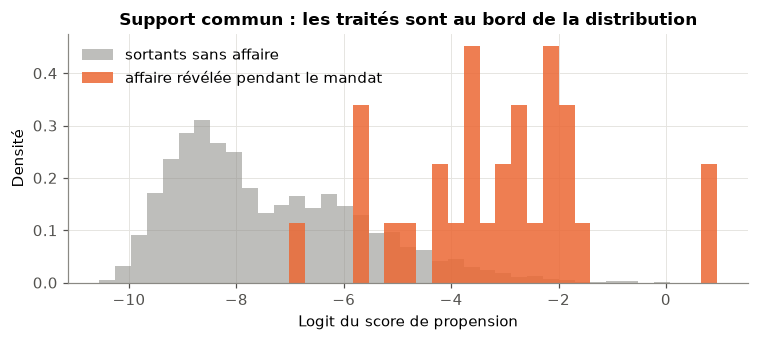

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.2))
s = app["score"]
bins = np.linspace(s.logit_ps.min(), s.logit_ps.max(), 40)
ax.hist(s.logit_ps[~s.traite], bins=bins, density=True, color=NEUTRE, alpha=0.55, label="sortants sans affaire")
ax.hist(s.logit_ps[s.traite], bins=bins, density=True, color=COULEURS[2026], alpha=0.85,
        label="affaire révélée pendant le mandat")
ax.set_xlabel("Logit du score de propension")
ax.set_ylabel("Densité")
ax.set_title("Support commun : les traités sont au bord de la distribution")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture.** L'appariement fonctionne techniquement : 28 des 30 traités trouvent des jumeaux, et après appariement les écarts standardisés sont tous inférieurs à 0,15 en valeur absolue (contre 2,2 pour la taille avant). Mais les traités occupent la queue droite de la distribution du score de propension : très peu de communes de sortants ordinaires leur ressemblent.

Résultat : face à des maires ordinaires de communes semblables, un sortant visé par une affaire révélée pendant le mandat perd 1,7 point de plus (IC de -6,3 à +3,4) et gagne 11 points moins souvent (IC de -30 à +6). Les deux intervalles contiennent zéro. C'est cohérent avec les régressions : comparé à des maires ordinaires, l'affaire ne laisse pas de trace nette, car la prime de notoriété la compense.

## 8. Selon le stade de l'affaire au moment du vote

Une simple plainte, une mise en examen et une condamnation ne pèsent sans doute pas
autant aux yeux des électeurs. On grade chaque affaire connue au vote selon son stade
**à la date du 1er tour** (`src/affaires.py`, fonction `niveau_au_vote`) :

| niveau | stade au vote | statuts |
|---|---|---|
| 1 | soupçon | signalement, plainte, enquête du parquet |
| 2 | procédure judiciaire | mise en examen, instruction, renvoi, procès ; affaire jugée après le vote |
| 3 | condamnation | condamnation prononcée avant le vote, même frappée d'appel |
| à part | blanchi | relaxe, non-lieu, classement sans suite prononcés avant le vote |

Un sortant reçoit le niveau le plus élevé de ses affaires connues. Les sources ne
donnent que le statut **actuel** : le stade au vote est reconstruit à partir de la date
du verdict. C'est une approximation prudente, car une affaire jugée après le vote est
classée au niveau 2 alors qu'elle n'en était peut-être qu'à l'enquête.

Deux spécifications, avec les contrôles du modèle (2) et la notoriété :

- **ordinale** : `affaire_niveau` de 0 à 3, un seul coefficient qui mesure ce que
  coûte chaque marche supplémentaire (effet « dose-réponse ») ;
- **par niveau** : une indicatrice par stade, plus souple. Soupçon et procédure ne
  comptent que quelques sortants chacun, presque tous réélus : on les regroupe en
  « avant jugement », sans quoi le logit ne converge pas.

Le groupe **blanchi** sert de test : si les électeurs sanctionnaient aussi un élu
relaxé, la sanction porterait sur la rumeur plus que sur la culpabilité.

In [12]:
stade = np.select(
    [d.affaire_blanchi == 1, d.affaire_condamnation == 1, d.affaire_procedure == 1, d.affaire_soupcon == 1,
     d.personnalite_affaires == 1],
    ["blanchi", "3 condamnation", "2 procédure", "1 soupçon", "0 personnalité, affaire future"],
    "sortant ordinaire")
(d.assign(stade=stade).groupby("stade")
 .agg(sortants=("code_insee", "size"), dont_2026=("election_2026", "sum"),
      inscrits=("inscrits", "median"), score_precedent=("pct_voix_exp_prec", "mean"),
      evolution_score=("delta_pct_voix_exp", "mean"), victoire=("gagne", "mean"))
 .round(2))

,sortants,dont_2026,inscrits,score_precedent,evolution_score,victoire
stade,,,,,,
"0 personnalité, affaire future",46,6,25936.5,50.13,1.04,0.93
1 soupçon,3,3,18343.0,53.31,-4.40,1.00
2 procédure,7,5,37588.0,51.27,1.69,0.86
3 condamnation,38,22,25216.5,49.70,-0.16,0.76
blanchi,9,7,25632.0,62.11,-6.21,0.89
sortant ordinaire,6669,3462,2586.0,62.10,-7.31,0.74


In [13]:
gradation = {
    "ordinal": M.GRADATION_ORDINALE,
    "par niveau": M.GRADATION_NIVEAUX,
}
res_gradation = {}
for spec, rhs in gradation.items():
    res_gradation[("évolution du score (pts)", spec)] = M.ols(f"delta_pct_voix_exp ~ {rhs} + {M.CONTROLES}", d)
    res_gradation[("victoire (effet marginal)", spec)] = M.logit(f"gagne ~ {rhs} + {M.CONTROLES}", d)
display(pd.concat({k: M.coefficients(r) for k, r in res_gradation.items()}).round(3))

# La condamnation coûte-t-elle plus qu'une affaire pas encore jugée ? (en points pour le score,
# sur l'échelle logit pour la victoire)
for (resultat, spec), r in res_gradation.items():
    if spec == "par niveau":
        test = r.t_test("affaire_condamnation - affaire_avant_jugement = 0")
        print(f"{resultat.split(' (')[0]} : condamnation - avant jugement = {test.effect[0]:.2f}, "
              f"p = {float(test.pvalue):.2f}")

coef  ic_bas  ic_haut      p
évolution du score (pts)  ordinal    affaire_niveau         -0.586  -2.526    1.355  0.554
                                     affaire_blanchi        -2.093  -9.563    5.378  0.583
                                     personnalite_affaires   6.981   3.145   10.818  0.000
victoire (effet marginal) ordinal    affaire_niveau         -0.092  -0.191    0.006  0.067
                                     affaire_blanchi        -0.172  -0.609    0.264  0.439
                                     personnalite_affaires   0.323   0.082    0.565  0.009
évolution du score (pts)  par niveau affaire_avant_jugement  1.973  -6.737   10.684  0.657
                                     affaire_condamnation   -1.862  -7.709    3.985  0.533
                                     affaire_blanchi        -1.814  -9.283    5.656  0.634
                                     personnalite_affaires   6.713   2.849   10.578  0.001
victoire (effet marginal) par niveau affaire_avant_jugement -0.082  -0.546    0.382  0.729
                                     affaire_condamnation   -0.261  -0.548    0.027  0.075
                                     affaire_blanchi        -0.155  -0.591    0.280  0.485
                                     personnalite_affaires   0.306   0.068    0.544  0.012

évolution du score : condamnation - avant jugement = -3.84, p = 0.42
victoire : condamnation - avant jugement = -0.98, p = 0.42


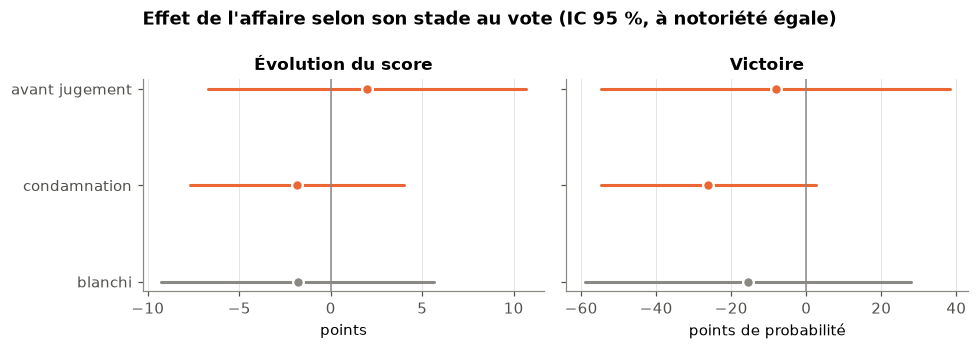

In [14]:
niveaux = {"affaire_avant_jugement": "avant jugement", "affaire_condamnation": "condamnation",
           "affaire_blanchi": "blanchi"}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, resultat, echelle in zip(axes, ("évolution du score (pts)", "victoire (effet marginal)"), (1, 100)):
    c = M.coefficients(res_gradation[(resultat, "par niveau")]).loc[list(niveaux)] * [echelle, echelle, echelle, 1]
    for y, (var, lib) in enumerate(niveaux.items()):
        couleur = NEUTRE if var == "affaire_blanchi" else COULEURS[2026]
        ax.plot([c.loc[var, "ic_bas"], c.loc[var, "ic_haut"]], [y, y], color=couleur, lw=2, solid_capstyle="round")
        ax.plot(c.loc[var, "coef"], y, "o", ms=7, color=couleur, mec="white", mew=1.5)
    ax.axvline(0, color=NEUTRE, lw=1)
    ax.grid(axis="y", visible=False)
    ax.set_yticks(range(len(niveaux)), list(niveaux.values()))
    ax.set_xlabel("points" if echelle == 1 else "points de probabilité")
    ax.set_title(resultat.split(" (")[0].capitalize())
axes[0].invert_yaxis()
fig.suptitle("Effet de l'affaire selon son stade au vote (IC 95 %, à notoriété égale)", fontweight="bold")
plt.tight_layout()
plt.show()

**Lecture.** Sur le champ des modèles, 38 sortants avaient été condamnés avant le vote, 10 avaient une affaire pas encore jugée (dont 3 au stade du simple soupçon) et 9 avaient été blanchis. La gradation est donc surtout une opposition « condamné / pas encore jugé », car Casier Politique ne recense que des condamnations.

- **Score.** Aucun stade ne coûte de voix de façon détectable. Chaque marche supplémentaire est associée à -0,6 point (IC 95 % de -2,5 à +1,4), et les écarts entre niveaux sont très loin d'être significatifs.
- **Victoire.** Les estimations vont dans le sens attendu : une affaire pas encore jugée réduit la probabilité de gagner de 8 points (non significatif), une condamnation de 26 points (IC de -55 à +3, p = 0,08), et chaque marche de 9 points (p = 0,07). Mais l'écart entre condamnation et affaire non jugée n'est pas significatif (p = 0,42) : on ne peut pas affirmer que les électeurs distinguent les stades.
- **Blanchis.** Les 9 élus relaxés avant le vote ne font pas significativement moins bien que des sortants comparables (-2 points de score, -16 points de victoire, intervalles très larges) : rien n'indique une sanction de la simple rumeur, sans pouvoir l'exclure.

La gradation confirme le constat principal : pas de sanction robuste sur le score. Le seul indice, fragile, porte sur la victoire des sortants déjà condamnés, à notoriété égale.


## 9. Robustesse

Avec si peu de traités, on vérifie que le résultat tient sur chaque élection.

**Élection par élection.** En 2026, la liste des sortants est officielle ; en 2020,
le sortant est approché par la tête de la liste gagnante de 2014. On ré-estime le
modèle (3) sur chaque élection, avec et sans la variable de notoriété. Il faut noter
qu'en 2026 presque aucune personnalité n'a encore d'affaire « future » (elles n'ont
pas eu le temps d'éclater) : la notoriété y est presque confondue avec l'affaire.

In [15]:
display(pd.crosstab(d.annee, [d.personnalite_affaires.map({0: "ordinaire", 1: "personnalité"}),
                              d.affaire_connue.map({0: "pas d'affaire connue", 1: "affaire connue"})]))
lignes = {}
controles_sans_annee = M.CONTROLES.replace(" + C(annee)", "")
for annee in (2020, 2026):
    x = d[d.annee == annee]
    for libelle, notoriete in (("sans notoriété", ""), ("avec notoriété", " + personnalite_affaires")):
        f = "delta_pct_voix_exp ~ affaire_mandat + affaire_avant_mandat" + notoriete + " + " + controles_sans_annee
        c = M.coefficients(M.ols(f, x)).loc["affaire_mandat"]
        lignes[(annee, libelle)] = c
pd.DataFrame(lignes).T.round(2)

personnalite_affaires            ordinaire   personnalité                     
affaire_connue        pas d'affaire connue affaire connue pas d'affaire connue
annee                                                                         
2020                                  3207             20                   40
2026                                  3462             37                    6

coef  ic_bas  ic_haut     p
2020 sans notoriété  2.14   -5.78    10.06  0.60
     avec notoriété -5.06  -13.42     3.31  0.24
2026 sans notoriété  3.76   -0.69     8.22  0.10
     avec notoriété  5.73   -5.84    17.30  0.33

**Lecture.** Ce tableau tempère fortement les résultats précédents.

- **Contre des maires ordinaires** (sans la variable de notoriété), une affaire révélée pendant le mandat n'est associée à aucune perte : +2 points en 2020, +3,8 points en 2026, non significatifs. La perte de 5 points observée en 2026 dans le notebook 03, à taille égale, **disparaît une fois le score précédent contrôlé**. Les sortants visés par une affaire avaient été moins bien élus la fois précédente (52 % contre 62 %), donc avaient moins à perdre : c'est le retour vers la moyenne, pas l'affaire.
- **À notoriété égale**, l'effet est négatif en 2020 (-5 points, non significatif) et positif en 2026, où la comparaison n'est de toute façon pas possible : il n'y reste que 6 personnalités sans affaire connue.

## Synthèse

| Approche | Comparaison | Score (pts) | Victoire (pts) |
|---|---|---|---|
| Stratification par taille (nb 03) | sortants sans affaire, même taille | -2,6 (ns) ; -5,3 en 2026 | -4 (ns) |
| Régression, contrôles sans notoriété (2026) | maires ordinaires à caractéristiques égales | +3,8 (ns) | |
| Régression (3) / logit (3) avec notoriété | personnalités sans affaire connue | -3,2 (ns) | -29 (p = 0,04) |
| Appariement sur score de propension | maires ordinaires de communes semblables | -1,7 (ns) | -11 (ns) |
| Gradation : condamnation avant le vote (logit par niveau) | personnalités sans affaire connue | -1,9 (ns) | -26 (p = 0,08) |

1. **Pas de sanction robuste.** Aucune approche ne met en évidence de façon solide une perte de voix des sortants visés par une affaire. La perte apparente de 2026 s'explique par le retour vers la moyenne : ces maires avaient été moins bien élus la fois précédente.
2. **La notoriété brouille les comparaisons.** Les personnalités recensées font nettement mieux que les maires ordinaires (+7 points de score, +30 points de probabilité de victoire), surtout en 2020.
3. **À notoriété égale, un indice de sanction sur la victoire** : environ -30 points, à la limite de la significativité (p = 0,04, mais fragile), et porté par l'élection de 2020.
4. **Pas de différence démontrée entre camps.** Les estimations suggèrent une sanction plus forte pour les sortants de gauche que pour ceux de droite, mais l'écart n'est pas significatif (11 sortants de gauche seulement). Il en va de même du délai écoulé depuis l'affaire et de la participation.
5. **Le stade de l'affaire ne change pas le constat.** Aucun stade ne coûte de voix. Une condamnation prononcée avant le vote réduirait la probabilité de victoire d'environ 26 points (p = 0,08), sans différence significative avec une affaire pas encore jugée ; les élus blanchis ne sont pas sanctionnés de façon détectable.
6. **Réponse à la question posée** : avec les données disponibles, les électeurs ne sanctionnent pas de manière détectable les maires visés par une affaire judiciaire. Au mieux, une sanction modérée est compensée par l'avantage dont jouissent ces élus notoires. Avec quelques dizaines de cas, une sanction de quelques points pourrait toutefois passer inaperçue : l'absence de preuve n'est pas la preuve de l'absence.